# Week5_ex1_analysis - Two Stacked Magnets: Attraction Force vs the Charge Model

![Week5_ex1 result](Images/Week5_ex1_result_image.png)

Two NdFe35 cylinders (18-sided polyhedra, circumradius 10 mm, height 15 mm) stacked on the z-axis with a 5 mm gap, Magnetostatic, virtual force on each magnet. The notebook creates both a `magnet_n` (+z) and a `magnet_s` (-z) material, but both magnets are assigned `magnet_n`, so they are magnetized the same way: the N face of the lower magnet faces the S face of the upper one, and they attract.

A permanent magnet can be replaced by magnetic surface charge ±M on its two end faces, and the force between two coaxial charged disks has a closed form as a Bessel integral. That gives an exact reference for rigid magnets. The prediction below (≈ 50 N attraction along z, equal and opposite on the two magnets) was written down before the FEM table was opened; the self-consistent correction in step 4 was added afterwards to explain the gap.

$$F_z=\mu_0M^2\pi a^2\left[2G(g+h)-G(g)-G(g+2h)\right],\qquad G(z)=\int_0^\infty\frac{J_1(ka)^2}{k}e^{-kz}\,dk$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import j1

# 1. FEM forces, read once from Force Table 1 in the AEDT GUI (Setup1 : LastAdaptive).
#    The table shows Force_x and Force_y in mN; converted to N here.
fem = pd.DataFrame({
    "Force_x [N]": [39.956050e-3, 38.295673e-3],
    "Force_y [N]": [-39.055868e-3, -8.720106e-3],
    "Force_z [N]": [46.819720, -46.872091],
    "Force_mag [N]": [46.819753, 46.872107],
}, index=["force_1 (lower magnet)", "force_2 (upper magnet)"])
fem["transverse / |Force_z| [%]"] = np.hypot(fem["Force_x [N]"], fem["Force_y [N]"]) / fem["Force_z [N]"].abs() * 100
F_fem = fem["Force_z [N]"].abs().mean()
fem

,Force_x [N],Force_y [N],Force_z [N],Force_mag [N],transverse / |Force_z| [%]
force_1 (lower magnet),0.039956,-0.039056,46.819720,46.819753,0.119338
force_2 (upper magnet),0.038296,-0.008720,-46.872091,46.872107,0.083794


Both magnets are pulled toward each other along z, and the two axial forces agree to 0.11%, which is about as well as the virtual-force calculation on separately meshed objects closes Newton's third law here. The sideways components are under 0.12% of the axial force, so they're mesh noise. The mean axial force, 46.85 N, is the value compared below.

In [2]:
# 2. Model constants -- NdFe35 mu_r read once from the AEDT material library, Hc as set in the original notebook
mu0 = 4e-7 * np.pi
mu_r, Hc = 1.0997785406, 890000
chi = mu_r - 1
h, g = 0.015, 0.005
r_circ, n_sides = 0.010, 18
area_ratio = n_sides / (2 * np.pi) * np.sin(2 * np.pi / n_sides)   # polyhedron radius is the circumradius
a_circle = r_circ
a_poly = r_circ * np.sqrt(area_ratio)                              # circle with the 18-gon's area

def hankel_int(f, a, u_max=400.0):
    # integrate f(k) over k in [0, u_max/a], split at every pi in u = k*a so quad never
    # sees more than one oscillation of J1; the tail beyond is below 1e-5 for every kernel here
    edges = np.arange(0.0, u_max + np.pi, np.pi) / a
    return sum(quad(f, lo, hi)[0] for lo, hi in zip(edges[:-1], edges[1:]))

def G(z, a):
    return hankel_int(lambda k: j1(k * a)**2 / k * np.exp(-k * z), a)

def force_z(M, a, gap=g):
    return mu0 * M**2 * np.pi * a**2 * (2 * G(gap + h, a) - G(gap, a) - G(gap + 2 * h, a))

# 3. Rigid magnets, M = mu_r * Hc = Br / mu0 (the blind prediction)
M0 = mu_r * Hc
F_circle = abs(force_z(M0, a_circle))
F_poly = abs(force_z(M0, a_poly))

The blind prediction assumed rigid magnets: M fixed at Br/μ0 = μr·Hc. NdFe35 in AEDT has a recoil permeability of 1.1, though, so the magnetization follows the local field, M = μr·Hc + (μr − 1)·H. Inside each magnet the field is mostly its own demagnetizing field, which points against M and lowers it; the other magnet's field points along M and raises it a little. For uniform M this gives

$$M=\frac{\mu_r H_c}{1+\chi N_{self}-\chi N_{mut}},\qquad \chi=\mu_r-1$$

where N_self is the volume-averaged demagnetizing factor of one cylinder and N_mut is the averaged field from the other magnet per unit M. Both follow from the same Bessel kernel, with the depth average done in closed form.

In [3]:
# 4. Self-consistent uniform magnetization (depth averages of e^{-kz} done analytically)
def N_self(a):
    f = lambda k: 2 * j1(k * a)**2 / k * (1 - np.exp(-k * h)) / (k * h)
    return hankel_int(f, a)

def N_mut(a, gap=g):
    f = lambda k: j1(k * a)**2 / k * (np.exp(-k * gap) - np.exp(-k * (gap + h))) * (1 - np.exp(-k * h)) / (k * h)
    return hankel_int(f, a)

ns, nm = N_self(a_poly), N_mut(a_poly)
M_sc = M0 / (1 + chi * ns - chi * nm)
F_sc = abs(force_z(M_sc, a_poly))

pd.DataFrame({
    "model": ["charge model, true circle, rigid M (blind)", "charge model, 18-gon area, rigid M (blind)",
              "18-gon area, self-consistent M", "FEM (mean of both magnets)"],
    "|Force_z| [N]": [F_circle, F_poly, F_sc, F_fem],
    "FEM / model - 1 [%]": [(F_fem / F_circle - 1) * 100, (F_fem / F_poly - 1) * 100, (F_fem / F_sc - 1) * 100, 0.0],
}).round(3)

,model,|Force_z| [N],FEM / model - 1 [%]
0,"charge model, true circle, rigid M (blind)",51.364,-8.796
1,"charge model, 18-gon area, rigid M (blind)",50.211,-6.703
2,"18-gon area, self-consistent M",47.311,-0.983
3,FEM (mean of both magnets),46.846,0.000


The polygon correction is the same one as in Week3_ex1: the 18-gon has 2.0% less area than its circumcircle, which takes about 2.2% off the force. That alone still leaves the FEM 6.7% below the rigid model. The magnets' own μr accounts for the rest. With N_self ≈ 0.37 and N_mut ≈ 0.07, M drops by about 2.9%, and since the force goes as M², that's close to 6% off the force. The self-consistent model lands 1% above the FEM.

The plot below runs both models over a range of gaps. The relative difference stays between 5% and 7%, because most of it comes from each magnet's own demagnetizing field, which doesn't depend on the spacing. It shrinks a little at close range, where the other magnet's field props the magnetization back up. The single FEM point is the 5 mm gap the notebook actually solves.

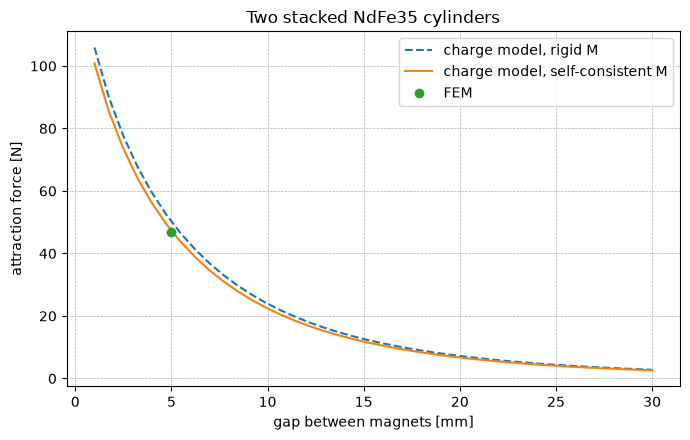

In [4]:
# 5. Force vs gap for both models, FEM point at the solved gap
gaps = np.linspace(0.001, 0.030, 40)
F_rigid_curve = [abs(force_z(M0, a_poly, gp)) for gp in gaps]
F_sc_curve = []
for gp in gaps:
    M_gp = M0 / (1 + chi * ns - chi * N_mut(a_poly, gp))
    F_sc_curve.append(abs(force_z(M_gp, a_poly, gp)))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(gaps * 1e3, F_rigid_curve, "--", label="charge model, rigid M")
ax.plot(gaps * 1e3, F_sc_curve, "-", label="charge model, self-consistent M")
ax.plot([g * 1e3], [F_fem], "o", label="FEM")
ax.set_xlabel("gap between magnets [mm]")
ax.set_ylabel("attraction force [N]")
ax.set_title("Two stacked NdFe35 cylinders")
ax.legend()
ax.grid(True, linestyle="--", linewidth=0.5)
fig.tight_layout()
plt.savefig("Images/Week5_ex1_force_vs_gap.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

The two magnets attract along z with 46.8 N on the lower one and 46.9 N on the upper one (0.11% apart), and the sideways components are below 0.12% of that. The blind charge-model prediction of about 50 N was 7% too high. The miss isn't in the solver. The prediction treated the magnets as rigid, while the AEDT NdFe35 has a recoil permeability of 1.1, so each magnet's own demagnetizing field lowers its magnetization by about 3%, and the force by about 6%. With that self-consistent magnetization and the 18-gon's area, the charge model is 1% above the FEM. That correction was worked out after seeing the FEM value, so it explains the gap rather than predicting it, but it uses nothing from the FEM except the comparison itself.

Two notes on the original notebook: the `magnet_s` material is created but never used (both magnets are `magnet_n`), which is why this is an attraction case, and the force report sweeps `m_h` over "All" without any parametric sweep, so it holds a single row. Neither affects this check, and nothing here needs further analysis.